Libraries loaded ✓
Dataset shape: (61200, 59)
Attack_group
Benign                   24000
DoS_DDoS                 12000
Malware                  12000
Information_Gathering     6000
Injection                 6000
MITM                      1200
Name: count, dtype: int64
Features   : 57
LOGO groups: ['DoS_DDoS', 'Malware', 'Information_Gathering', 'Injection', 'MITM']
Classes    : ['Benign', 'DoS_DDoS', 'Information_Gathering', 'Injection', 'MITM', 'Malware']
TAHAP 0: CLOSED-WORLD BASELINE (5-Fold Cross Validation)
Setting: semua attack group tersedia di training

  XGBoost        : F1=0.9158 ± 0.0036 | Acc=0.9557 | Time=26.7s
  LightGBM       : F1=0.9162 ± 0.0026 | Acc=0.9562 | Time=19.6s
  CatBoost       : F1=0.9153 ± 0.0024 | Acc=0.9553 | Time=31.0s
  RandomForest   : F1=0.8941 ± 0.0030 | Acc=0.9401 | Time=15.1s

Best model (closed-world): LightGBM (F1=0.9162)

TAHAP 1: LOGO (Leave-One-Group-Out) EVALUATION
Setting: 1 attack group disembunyikan dari training

── Held-out: DoS_DDoS ──

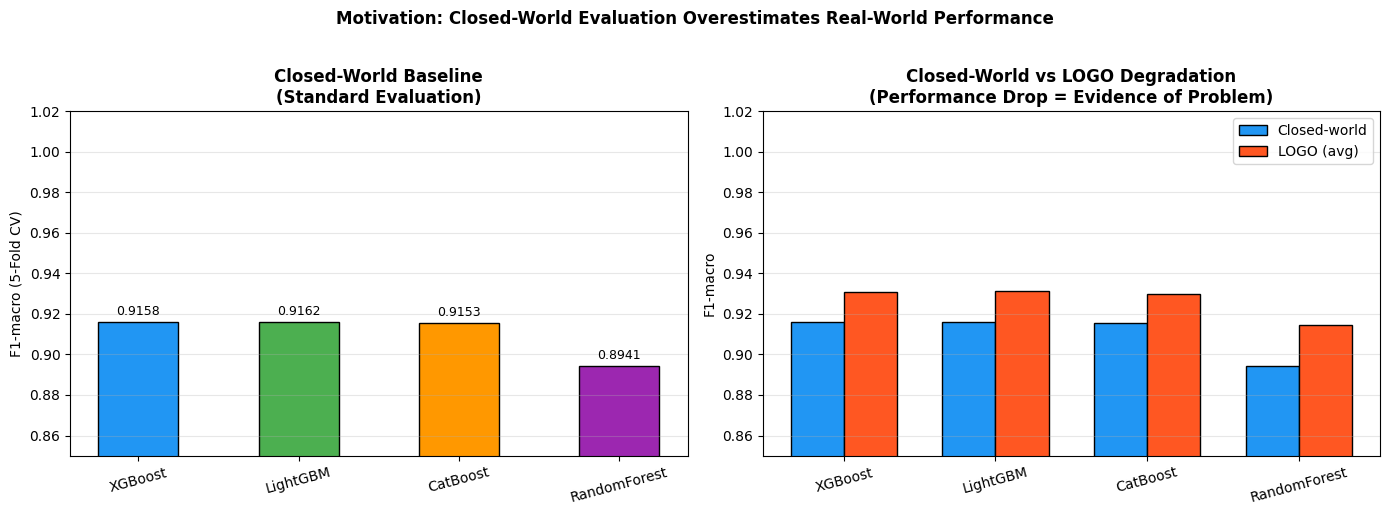

Saved: closedworld_vs_logo.png ✓


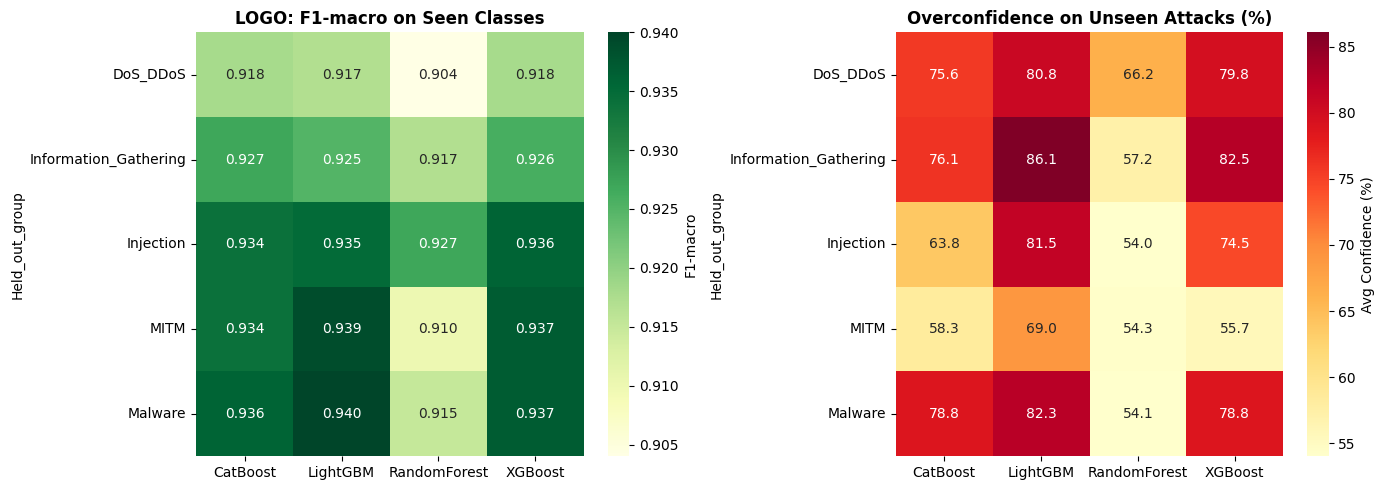

Saved: logo_heatmaps.png ✓


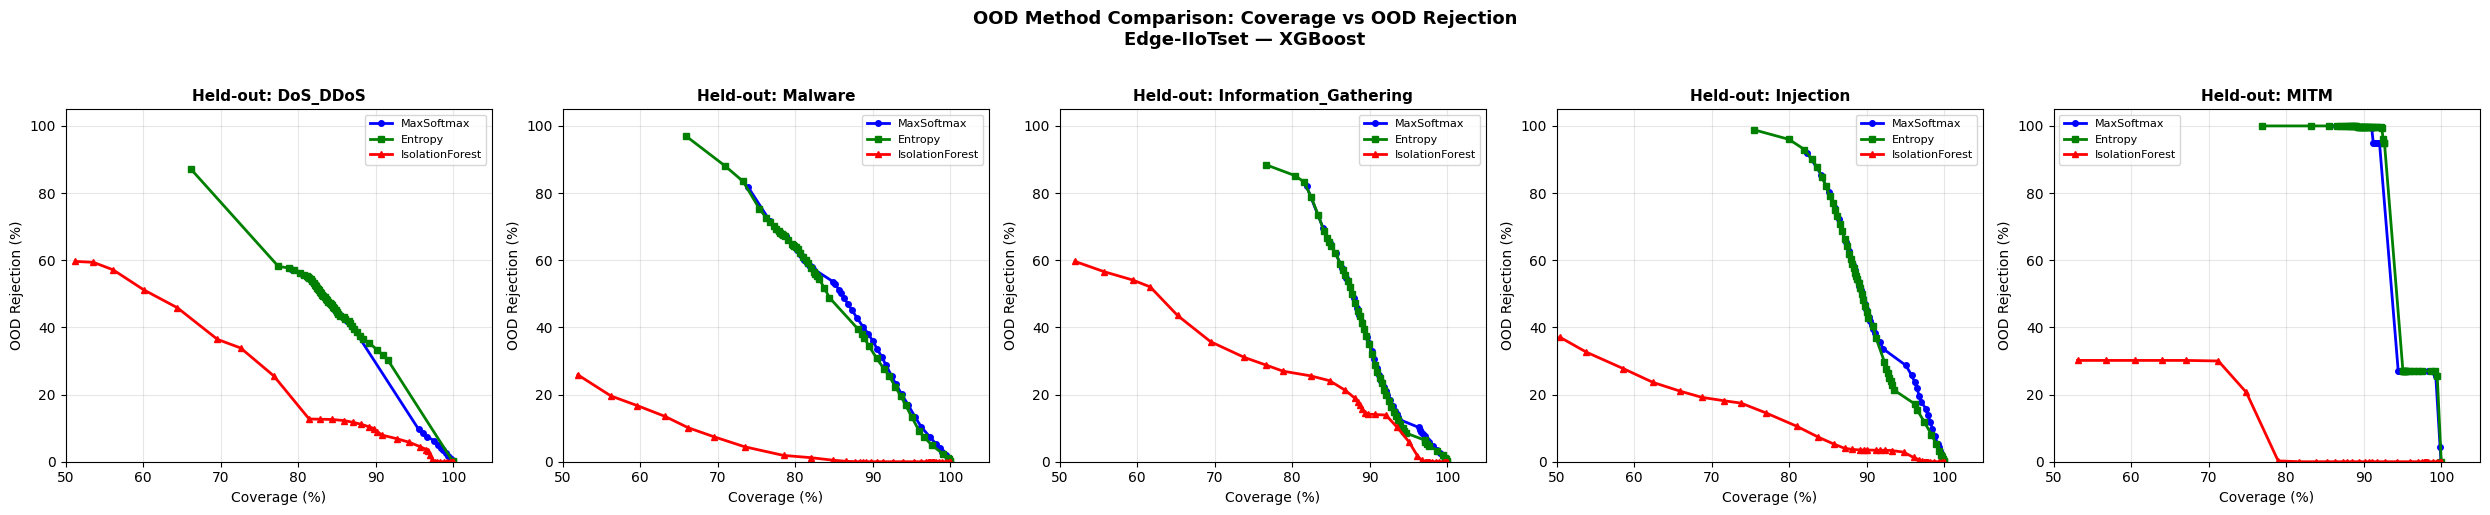

Saved: ood_comparison.png ✓


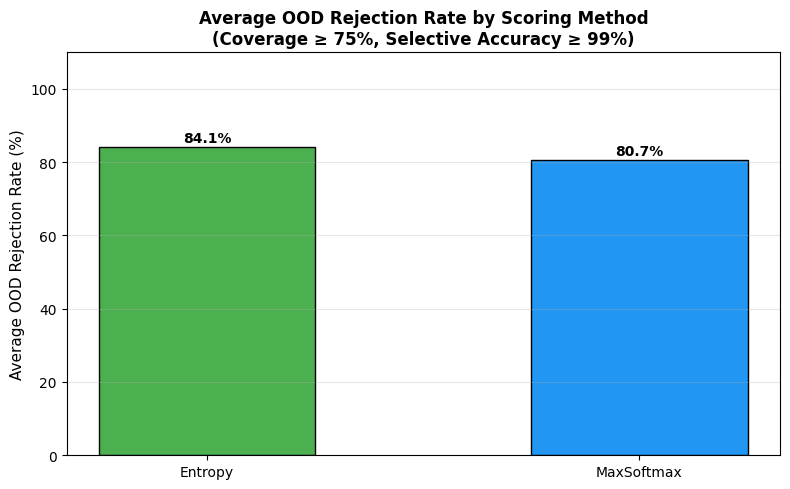

Saved: method_comparison_bar.png ✓

FINAL SUMMARY

[TAHAP 0] Closed-World Baseline (5-Fold CV):
       Model  F1_macro  F1_std  Accuracy
     XGBoost    0.9158  0.0036    0.9557
    LightGBM    0.9162  0.0026    0.9562
    CatBoost    0.9153  0.0024    0.9553
RandomForest    0.8941  0.0030    0.9401

[TAHAP 1] LOGO — F1 on Seen Classes:
Model                  CatBoost  LightGBM  RandomForest  XGBoost
Held_out_group                                                  
DoS_DDoS                 0.9177    0.9174        0.9042   0.9178
Information_Gathering    0.9267    0.9247        0.9171   0.9264
Injection                0.9340    0.9353        0.9270   0.9357
MITM                     0.9343    0.9390        0.9105   0.9368
Malware                  0.9362    0.9405        0.9147   0.9373

[TAHAP 1] LOGO — Overconfidence on Unseen Attacks (%):
Model                  CatBoost  LightGBM  RandomForest  XGBoost
Held_out_group                                                  
DoS_DDoS            

In [1]:
# ============================================================
# NOTEBOOK B v3: LOGO + SELECTIVE CLASSIFICATION + CLOSED-WORLD
# 3 OOD Scoring Methods: Max Softmax, Entropy, Isolation Forest
# + Closed-world baseline untuk perbandingan
# ============================================================

# ── CELL 1: Import ────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, accuracy_score, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
import warnings, time
warnings.filterwarnings('ignore')

print("Libraries loaded ✓")


# ── CELL 2: Load & Clean Data ─────────────────────────────────
FILE_PATH = '/kaggle/input/datasets/USERNAME/dataset-edge-iiotset-clean/edge_iiotset_clean.csv'

df = pd.read_csv(FILE_PATH)
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.fillna(0, inplace=True)
for col in df.select_dtypes(include=[np.number]).columns:
    df[col] = df[col].clip(-1e15, 1e15)

print(f"Dataset shape: {df.shape}")
print(df['Attack_group'].value_counts())


# ── CELL 3: Setup ─────────────────────────────────────────────
FEATURE_COLS = [col for col in df.columns
                if col not in ['Attack_type', 'Attack_group']]
GROUPS = [g for g in df['Attack_group'].unique() if g != 'Benign']

le_global = LabelEncoder()
df['label'] = le_global.fit_transform(df['Attack_group'])

print(f"Features   : {len(FEATURE_COLS)}")
print(f"LOGO groups: {GROUPS}")
print(f"Classes    : {list(le_global.classes_)}")


# ── CELL 4: Define Models ─────────────────────────────────────
def get_models():
    return {
        'XGBoost': xgb.XGBClassifier(
            n_estimators=200, max_depth=6, learning_rate=0.1,
            use_label_encoder=False, eval_metric='mlogloss',
            random_state=42, n_jobs=-1, verbosity=0),
        'LightGBM': lgb.LGBMClassifier(
            n_estimators=200, max_depth=6, learning_rate=0.1,
            random_state=42, n_jobs=-1, verbose=-1),
        'CatBoost': CatBoostClassifier(
            iterations=200, depth=6, learning_rate=0.1,
            random_state=42, verbose=0),
        'RandomForest': RandomForestClassifier(
            n_estimators=200, max_depth=12,
            random_state=42, n_jobs=-1),
    }


# ── CELL 5: CLOSED-WORLD BASELINE (5-Fold CV) ────────────────
print("=" * 60)
print("TAHAP 0: CLOSED-WORLD BASELINE (5-Fold Cross Validation)")
print("=" * 60)
print("Setting: semua attack group tersedia di training\n")

X_all = df[FEATURE_COLS].values.astype(np.float64)
y_all = df['label'].values

cw_results = []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for model_name, model in get_models().items():
    fold_f1s  = []
    fold_accs = []
    t0 = time.time()

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all)):
        model.fit(X_all[tr_idx], y_all[tr_idx])
        y_pred = model.predict(X_all[te_idx])
        fold_f1s.append(f1_score(y_all[te_idx], y_pred, average='macro'))
        fold_accs.append(accuracy_score(y_all[te_idx], y_pred))

    elapsed = time.time() - t0
    mean_f1  = np.mean(fold_f1s)
    std_f1   = np.std(fold_f1s)
    mean_acc = np.mean(fold_accs)

    cw_results.append({
        'Model':    model_name,
        'F1_macro': round(mean_f1, 4),
        'F1_std':   round(std_f1, 4),
        'Accuracy': round(mean_acc, 4),
        'Time_s':   round(elapsed, 1),
    })
    print(f"  {model_name:15s}: F1={mean_f1:.4f} ± {std_f1:.4f} | "
          f"Acc={mean_acc:.4f} | Time={elapsed:.1f}s")

cw_df = pd.DataFrame(cw_results)
print(f"\nBest model (closed-world): "
      f"{cw_df.loc[cw_df['F1_macro'].idxmax(), 'Model']} "
      f"(F1={cw_df['F1_macro'].max():.4f})")


# ── CELL 6: LOGO Evaluation ───────────────────────────────────
print("\n" + "=" * 60)
print("TAHAP 1: LOGO (Leave-One-Group-Out) EVALUATION")
print("=" * 60)
print("Setting: 1 attack group disembunyikan dari training\n")

logo_results = []

for held_out in GROUPS:
    print(f"── Held-out: {held_out} ──")

    train_df = df[df['Attack_group'] != held_out].copy()
    test_df  = df[df['Attack_group'] == held_out].copy()

    le_logo      = LabelEncoder()
    y_train_full = le_logo.fit_transform(train_df['Attack_group'])
    X_train_full = train_df[FEATURE_COLS].values.astype(np.float64)
    X_test       = test_df[FEATURE_COLS].values.astype(np.float64)

    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train_full, y_train_full,
        test_size=0.2, random_state=42, stratify=y_train_full)

    for model_name, model in get_models().items():
        t0 = time.time()
        model.fit(X_tr, y_tr)
        train_time = time.time() - t0

        y_val_pred   = model.predict(X_val)
        f1_seen      = f1_score(y_val, y_val_pred, average='macro')
        acc_seen     = accuracy_score(y_val, y_val_pred)

        max_proba_unseen = np.nan
        if hasattr(model, 'predict_proba'):
            proba_unseen     = model.predict_proba(X_test)
            max_proba_unseen = proba_unseen.max(axis=1).mean()

        logo_results.append({
            'Held_out_group':           held_out,
            'Model':                    model_name,
            'F1_seen_macro':            round(f1_seen, 4),
            'Accuracy_seen':            round(acc_seen, 4),
            'Avg_confidence_on_unseen': round(max_proba_unseen * 100, 2),
            'Train_time_s':             round(train_time, 2),
        })
        print(f"  {model_name:15s}: F1={f1_seen:.4f} | "
              f"Conf_unseen={max_proba_unseen*100:.1f}% | "
              f"Time={train_time:.1f}s")

logo_df = pd.DataFrame(logo_results)

print("\n=== F1 on Seen Classes (LOGO) ===")
print(logo_df.pivot_table(
    values='F1_seen_macro',
    index='Held_out_group', columns='Model').round(4))

print("\n=== Overconfidence on Unseen Attacks (%) ===")
print(logo_df.pivot_table(
    values='Avg_confidence_on_unseen',
    index='Held_out_group', columns='Model').round(2))

# Perbandingan closed-world vs LOGO
print("\n=== CLOSED-WORLD vs LOGO DEGRADATION ===")
print(f"{'Model':<15} {'CW F1':>8} {'LOGO F1 (avg)':>14} {'Degradation':>12}")
print("-" * 52)
for _, cw_row in cw_df.iterrows():
    m = cw_row['Model']
    logo_avg = logo_df[logo_df['Model'] == m]['F1_seen_macro'].mean()
    deg = cw_row['F1_macro'] - logo_avg
    print(f"{m:<15} {cw_row['F1_macro']:>8.4f} {logo_avg:>14.4f} {deg:>11.4f}")


# ── CELL 7: Helper OOD Sweep ──────────────────────────────────
def sweep_ood(scores, y_group_test, y_pred_labels,
              held_out, higher_is_confident=True, n_steps=50):
    if higher_is_confident:
        thresholds = np.linspace(scores.min(), scores.max(), n_steps)
    else:
        thresholds = np.linspace(scores.max(), scores.min(), n_steps)

    is_unseen = (y_group_test == held_out)
    rows = []

    for thresh in thresholds:
        accepted = scores >= thresh if higher_is_confident else scores <= thresh
        coverage = accepted.mean() * 100
        if accepted.sum() < 10:
            continue

        seen_accepted = accepted & ~is_unseen
        if seen_accepted.sum() > 0:
            correct = (y_pred_labels[seen_accepted] ==
                       y_group_test[seen_accepted]).sum()
            sel_acc = correct / seen_accepted.sum() * 100
        else:
            sel_acc = 0.0

        unseen_accepted = is_unseen & accepted
        ood_rej = (1 - unseen_accepted.sum() / is_unseen.sum()) * 100 \
                  if is_unseen.sum() > 0 else 0.0

        rows.append({
            'threshold':             round(float(thresh), 4),
            'coverage_%':           round(coverage, 2),
            'selective_accuracy_%': round(sel_acc, 2),
            'ood_rejection_%':      round(ood_rej, 2),
        })

    return pd.DataFrame(rows)


# ── CELL 8: 3 OOD Methods ────────────────────────────────────
print("\n" + "=" * 60)
print("TAHAP 2: SELECTIVE CLASSIFICATION — 3 OOD METHODS")
print("=" * 60)
print("Methods: (1) Max Softmax  (2) Entropy  (3) Isolation Forest\n")

sc_all      = {g: {} for g in GROUPS}
summary_rows = []

for held_out in GROUPS:
    print(f"── Held-out: {held_out} ──")

    train_df     = df[df['Attack_group'] != held_out].copy()
    test_df      = df.copy()

    le_sc        = LabelEncoder()
    y_train      = le_sc.fit_transform(train_df['Attack_group'])
    X_train      = train_df[FEATURE_COLS].values.astype(np.float64)
    X_test       = test_df[FEATURE_COLS].values.astype(np.float64)
    y_group_test = test_df['Attack_group'].values

    # Train XGBoost
    clf = xgb.XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        use_label_encoder=False, eval_metric='mlogloss',
        random_state=42, n_jobs=-1, verbosity=0)
    clf.fit(X_train, y_train)

    proba         = clf.predict_proba(X_test)
    y_pred_enc    = clf.predict(X_test)
    y_pred_labels = le_sc.inverse_transform(y_pred_enc)
    eps           = 1e-10

    # Method 1: Max Softmax
    score_softmax = proba.max(axis=1)
    df_m1 = sweep_ood(score_softmax, y_group_test, y_pred_labels,
                      held_out, higher_is_confident=True)
    sc_all[held_out]['MaxSoftmax'] = df_m1

    # Method 2: Entropy
    entropy  = -np.sum(proba * np.log(proba + eps), axis=1)
    df_m2 = sweep_ood(entropy, y_group_test, y_pred_labels,
                      held_out, higher_is_confident=False)
    sc_all[held_out]['Entropy'] = df_m2

    # Method 3: Isolation Forest
    iso = IsolationForest(n_estimators=200, contamination='auto',
                          random_state=42, n_jobs=-1)
    iso.fit(X_train)
    score_iso = iso.decision_function(X_test)
    df_m3 = sweep_ood(score_iso, y_group_test, y_pred_labels,
                      held_out, higher_is_confident=True)
    sc_all[held_out]['IsolationForest'] = df_m3

    # Optimal per method
    for method_name, df_m in [('MaxSoftmax',     df_m1),
                               ('Entropy',         df_m2),
                               ('IsolationForest', df_m3)]:
        opt = df_m[(df_m['coverage_%'] >= 75) &
                   (df_m['selective_accuracy_%'] >= 99.0)]
        if len(opt) > 0:
            best = opt.sort_values('ood_rejection_%', ascending=False).iloc[0]
            summary_rows.append({
                'Held_out':   held_out,
                'Method':     method_name,
                'Threshold':  best['threshold'],
                'Coverage_%': best['coverage_%'],
                'Sel_Acc_%':  best['selective_accuracy_%'],
                'OOD_Rej_%':  best['ood_rejection_%'],
            })
            print(f"  {method_name:20s}: Coverage={best['coverage_%']:.1f}% | "
                  f"Sel.Acc={best['selective_accuracy_%']:.1f}% | "
                  f"OOD Rej={best['ood_rejection_%']:.1f}%")
        else:
            print(f"  {method_name:20s}: No optimal threshold found")

summary_df = pd.DataFrame(summary_rows)

print("\n=== OOD Rejection per Method ===")
if len(summary_df) > 0:
    pivot = summary_df.pivot_table(
        values='OOD_Rej_%',
        index='Held_out', columns='Method').round(2)
    print(pivot)
    print("\n=== Average OOD Rejection ===")
    print(pivot.mean().round(2))
    best_method = pivot.mean().idxmax()
    print(f"\n✅ Best OOD Method: {best_method} "
          f"(avg {pivot.mean().max():.1f}%)")


# ── CELL 9: Visualisasi ───────────────────────────────────────
print("\nMembuat visualisasi...")

# --- Figure 1: Closed-world vs LOGO comparison ---
fig1, axes1 = plt.subplots(1, 2, figsize=(14, 5))

# Bar: Closed-world F1
x = np.arange(len(cw_df))
bars = axes1[0].bar(cw_df['Model'], cw_df['F1_macro'],
                    color=['#2196F3','#4CAF50','#FF9800','#9C27B0'],
                    width=0.5, edgecolor='black')
for bar, val, std in zip(bars, cw_df['F1_macro'], cw_df['F1_std']):
    axes1[0].text(bar.get_x() + bar.get_width()/2,
                  bar.get_height() + 0.002,
                  f'{val:.4f}', ha='center', va='bottom', fontsize=9)
axes1[0].set_ylim([0.85, 1.02])
axes1[0].set_ylabel('F1-macro (5-Fold CV)')
axes1[0].set_title('Closed-World Baseline\n(Standard Evaluation)',
                   fontweight='bold')
axes1[0].grid(axis='y', alpha=0.3)
axes1[0].tick_params(axis='x', rotation=15)

# Grouped bar: CW vs LOGO per model
models_list = cw_df['Model'].tolist()
cw_f1s   = cw_df['F1_macro'].tolist()
logo_avg  = [logo_df[logo_df['Model']==m]['F1_seen_macro'].mean()
             for m in models_list]

x = np.arange(len(models_list))
w = 0.35
axes1[1].bar(x - w/2, cw_f1s,  w, label='Closed-world', color='#2196F3', edgecolor='black')
axes1[1].bar(x + w/2, logo_avg, w, label='LOGO (avg)',   color='#FF5722', edgecolor='black')
axes1[1].set_xticks(x)
axes1[1].set_xticklabels(models_list, rotation=15)
axes1[1].set_ylim([0.85, 1.02])
axes1[1].set_ylabel('F1-macro')
axes1[1].set_title('Closed-World vs LOGO Degradation\n(Performance Drop = Evidence of Problem)',
                   fontweight='bold')
axes1[1].legend()
axes1[1].grid(axis='y', alpha=0.3)

plt.suptitle('Motivation: Closed-World Evaluation Overestimates Real-World Performance',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('closedworld_vs_logo.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: closedworld_vs_logo.png ✓")

# --- Figure 2: LOGO Heatmaps ---
fig2, axes2 = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    logo_df.pivot_table(values='F1_seen_macro',
                        index='Held_out_group', columns='Model').round(3),
    annot=True, fmt='.3f', cmap='YlGn', ax=axes2[0],
    cbar_kws={'label': 'F1-macro'})
axes2[0].set_title('LOGO: F1-macro on Seen Classes', fontweight='bold')
axes2[0].set_xlabel('')

sns.heatmap(
    logo_df.pivot_table(values='Avg_confidence_on_unseen',
                        index='Held_out_group', columns='Model').round(1),
    annot=True, fmt='.1f', cmap='YlOrRd', ax=axes2[1],
    cbar_kws={'label': 'Avg Confidence (%)'})
axes2[1].set_title('Overconfidence on Unseen Attacks (%)', fontweight='bold')
axes2[1].set_xlabel('')

plt.tight_layout()
plt.savefig('logo_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: logo_heatmaps.png ✓")

# --- Figure 3: OOD Method Comparison ---
METHOD_STYLE = {
    'MaxSoftmax':     ('blue',  'b-o'),
    'Entropy':        ('green', 'g-s'),
    'IsolationForest':('red',   'r-^'),
}

n_groups = len(GROUPS)
fig3, axes3 = plt.subplots(1, n_groups, figsize=(5 * n_groups, 5))
if n_groups == 1:
    axes3 = [axes3]

for ax, held_out in zip(axes3, GROUPS):
    for method_name, (color, style) in METHOD_STYLE.items():
        df_m    = sc_all[held_out].get(method_name, pd.DataFrame())
        df_plot = df_m[df_m['coverage_%'] >= 50] if len(df_m) > 0 else pd.DataFrame()
        if len(df_plot) == 0:
            continue
        ax.plot(df_plot['coverage_%'], df_plot['ood_rejection_%'],
                style, linewidth=2, markersize=4,
                label=method_name, color=color)

    ax.set_xlabel('Coverage (%)', fontsize=10)
    ax.set_ylabel('OOD Rejection (%)', fontsize=10)
    ax.set_title(f'Held-out: {held_out}', fontsize=11, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_xlim([50, 105])
    ax.set_ylim([0, 105])

plt.suptitle('OOD Method Comparison: Coverage vs OOD Rejection\nEdge-IIoTset — XGBoost',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('ood_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: ood_comparison.png ✓")

# --- Figure 4: Average OOD Rejection Bar ---
if len(summary_df) > 0:
    fig4, ax4 = plt.subplots(figsize=(8, 5))
    avg_ood = summary_df.groupby('Method')['OOD_Rej_%'].mean().sort_values(ascending=False)
    colors_bar = ['#4CAF50', '#2196F3', '#F44336'][:len(avg_ood)]
    bars4 = ax4.bar(avg_ood.index, avg_ood.values,
                    color=colors_bar, width=0.5, edgecolor='black')
    for bar, val in zip(bars4, avg_ood.values):
        ax4.text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.5,
                 f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')
    ax4.set_ylabel('Average OOD Rejection Rate (%)', fontsize=11)
    ax4.set_title('Average OOD Rejection Rate by Scoring Method\n'
                  '(Coverage ≥ 75%, Selective Accuracy ≥ 99%)',
                  fontsize=12, fontweight='bold')
    ax4.set_ylim([0, 110])
    ax4.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('method_comparison_bar.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved: method_comparison_bar.png ✓")


# ── CELL 10: Final Summary ────────────────────────────────────
print("\n" + "="*60)
print("FINAL SUMMARY")
print("="*60)

print("\n[TAHAP 0] Closed-World Baseline (5-Fold CV):")
print(cw_df[['Model','F1_macro','F1_std','Accuracy']].to_string(index=False))

print("\n[TAHAP 1] LOGO — F1 on Seen Classes:")
print(logo_df.pivot_table(
    values='F1_seen_macro',
    index='Held_out_group', columns='Model').round(4))

print("\n[TAHAP 1] LOGO — Overconfidence on Unseen Attacks (%):")
print(logo_df.pivot_table(
    values='Avg_confidence_on_unseen',
    index='Held_out_group', columns='Model').round(2))

print("\n[DEGRADATION] Closed-World F1 vs LOGO F1 (avg):")
print(f"{'Model':<15} {'CW F1':>8} {'LOGO F1':>8} {'Drop':>8}")
print("-"*42)
for _, row in cw_df.iterrows():
    m        = row['Model']
    logo_avg = logo_df[logo_df['Model']==m]['F1_seen_macro'].mean()
    drop     = row['F1_macro'] - logo_avg
    print(f"{m:<15} {row['F1_macro']:>8.4f} {logo_avg:>8.4f} {drop:>8.4f}")

if len(summary_df) > 0:
    print("\n[TAHAP 2] OOD Rejection per Method (Coverage ≥ 75%, Sel.Acc ≥ 99%):")
    print(summary_df.pivot_table(
        values='OOD_Rej_%',
        index='Held_out', columns='Method').round(2))
    print("\nAverage OOD Rejection:")
    avg = summary_df.groupby('Method')['OOD_Rej_%'].mean().round(2)
    print(avg)
    print(f"\n✅ Best Method: {avg.idxmax()} ({avg.max():.1f}%)")


# ── CELL 11: Save All Results ─────────────────────────────────
cw_df.to_csv('closedworld_results.csv', index=False)
logo_df.to_csv('logo_results.csv', index=False)
if len(summary_df) > 0:
    summary_df.to_csv('sc_summary.csv', index=False)

for held_out in GROUPS:
    for method_name, df_m in sc_all[held_out].items():
        df_m.to_csv(f'sc_{held_out}_{method_name}.csv', index=False)

print("\n✅ Saved: closedworld_results.csv")
print("✅ Saved: logo_results.csv")
print("✅ Saved: sc_summary.csv")
print("✅ Saved: sc_[group]_[method].csv")
print("✅ Saved: closedworld_vs_logo.png")
print("✅ Saved: logo_heatmaps.png")
print("✅ Saved: ood_comparison.png")
print("✅ Saved: method_comparison_bar.png")
print("\nEKSPERIMEN SELESAI!")

In [2]:
# ── CELL TERAKHIR: ZIP SEMUA OUTPUT ──────────────────────────
import os, glob, zipfile
from datetime import datetime

zip_name = f'hasil_eksperimen_judul3_{datetime.now().strftime("%Y%m%d_%H%M")}.zip'

# Kumpulkan semua file output
files = (
    ['closedworld_results.csv',
     'logo_results.csv',
     'sc_summary.csv',
     'closedworld_vs_logo.png',
     'logo_heatmaps.png',
     'ood_comparison.png',
     'method_comparison_bar.png']
    + glob.glob('sc_*.csv')
)

with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for f in files:
        if os.path.exists(f):
            zf.write(f)
            print(f"✅ Added: {f}")
        else:
            print(f"⚠️  Not found: {f}")

size_kb = os.path.getsize(zip_name) / 1024
print(f"\n📦 Saved: {zip_name} ({size_kb:.1f} KB)")
print("Download dari panel Output di sidebar kanan Kaggle.")

✅ Added: closedworld_results.csv
✅ Added: logo_results.csv
✅ Added: sc_summary.csv
✅ Added: closedworld_vs_logo.png
✅ Added: logo_heatmaps.png
✅ Added: ood_comparison.png
✅ Added: method_comparison_bar.png
✅ Added: sc_MITM_MaxSoftmax.csv
✅ Added: sc_Injection_IsolationForest.csv
✅ Added: sc_summary.csv
✅ Added: sc_Injection_MaxSoftmax.csv
✅ Added: sc_Malware_MaxSoftmax.csv
✅ Added: sc_Information_Gathering_Entropy.csv
✅ Added: sc_Malware_Entropy.csv
✅ Added: sc_DoS_DDoS_MaxSoftmax.csv
✅ Added: sc_Information_Gathering_IsolationForest.csv
✅ Added: sc_Information_Gathering_MaxSoftmax.csv
✅ Added: sc_MITM_Entropy.csv
✅ Added: sc_MITM_IsolationForest.csv
✅ Added: sc_DoS_DDoS_IsolationForest.csv
✅ Added: sc_Injection_Entropy.csv
✅ Added: sc_DoS_DDoS_Entropy.csv
✅ Added: sc_Malware_IsolationForest.csv

📦 Saved: hasil_eksperimen_judul3_20260913_0857.zip (391.5 KB)
Download dari panel Output di sidebar kanan Kaggle.
